# SynCOM tests: periodic blobs (v3-periodic_blobs)

This notebook checks the changes from **v2-fixed** to **v3-periodic_blobs**, and shows the new behaviour with plots. Each section has:
- **Change**: what was changed and why.
- **Physics**: what the model should do physically.
- **Expected**: what the test checks.
- **Observed**: what the run actually showed.

Each section ends in an `assert`, so running the whole notebook without errors means every check passed.

### The two problems in v2-fixed
1. **Blobs ran out before the end of the simulation.** Each blob was a fixed train of 7 copies at $r + n(Pv + L)$, $n = 0, \pm2, \pm4, \pm6$, carried outward rigidly. No new copy was ever released, so after a few hours of simulated time most position angles were dark.
2. **Wrong launch radius.** `radial_i = 5 R☉ / Δr = 352 px` counted the 5 R☉ offset twice, because pixel 0 of the polar image is already 5 R☉. Blobs started at about 9.9 R☉.

### The v3 model
Every blob is a source that launches a blob **each time its period is up**: at $\tau = \ldots, -P, 0, P, 2P, \ldots$ on the blob's own clock $\tau = t + t_0$. The source was already launching before the first frame and keeps launching until the last. **A blob begins from its centre:** at the moment of launch its centre is at $r_0 = -12L$ px, six radial widths ($6 \times 2L$) below 5 R☉, behind the occulter. It slides into the field fully formed. Launch number $k$ (its centre) is at

$$r_k(\tau) = r_0 + v\,(\tau - kP),\qquad k_\text{lo} \le k \le k_\text{hi} = \lfloor \tau / P \rfloor ,$$

where $k_\text{lo}$ is the oldest launch still inside the image. It is negative when launches from before the first frame are still in the field. One blob's launches are $\lambda = vP$ apart along the radius. At a fixed radius, the brightness repeats every $P$.

| section | test |
|---|---|
| 1 | `gaussian_profile`: shape and wrap-around at 0°/360° |
| 2 | v2 against v3: the field stays full, from the first frame |
| 3 | launch behind the occulter: equal brightness at every radius |
| 4 | one blob, $P$ = 1 h: it reappears every period |
| 5 | periodicity in the cube (radius–time diagrams) |
| 6 | frequencies in the images against `syncom_load` (Fourier power spectrum) |
| 7 | the 30-frame FITS sample |
| 8 | storage (for reference; no compression is applied) |
| 9 | summary |


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from astropy.io import fits
from punchbowl.data.visualize import cmap_punch

from syncom_prams import default_syncom_prams, POLAR_PHI_RANGE, POLAR_RHO_RANGE
from syncom_load import syncom_load, syncom_blob_table
from gaussian_function import gaussian_profile
from syncom_image import syncom_image, angular_profiles, launch_range
from syncom_fits import load_fits_cube
from syncom_path import syncom_run_name, syncom_run_dir
from polar_to_rect import polar_to_rect
from syncom_movie import plot_rect_image

# Reference run of these tests: 2000 blobs, scale factor 2 (section 6c analyses the main notebook's 10000-blob run)
N_BLOBS, SCALE = 2000, 2.0
params = default_syncom_prams(SYNCOM_N_BLOBS=N_BLOBS, SYNCOM_SCALE_FACTOR=SCALE)
load_struc = syncom_load(params, simple=True)
blobs = syncom_blob_table(params, load_struc, SCALE)

NX, NY = params["syncom_nx"], params["syncom_ny"]
DR = params["syncom_pixel"]                 # [Rsun/px]
CADENCE = params["syncom_cadence"]          # [s/frame]
FRAMES = np.arange(300)                     # time steps of the main run

def to_rsun(pixel):
    """Radial pixel -> distance from the Sun centre [Rsun] (pixel 0 = POLAR_RHO_RANGE[0])."""
    return POLAR_RHO_RANGE[0] + np.asarray(pixel) * DR

assert np.isclose(to_rsun(NY - 1), POLAR_RHO_RANGE[1])     # plots and simulation use the same radial range

print(f"{N_BLOBS} blobs: v = {blobs['v'].min():.2f}-{blobs['v'].max():.2f} px/frame, "
      f"P = {blobs['period'].min():.1f}-{blobs['period'].max():.1f} frames, L = {blobs['L'].min():.1f}-{blobs['L'].max():.1f} px")

No file or date entered. Using default: syncom_20140414_densfix.sav
2000 blobs: v = 4.56-10.63 px/frame, P = 18.0-36.0 frames, L = 2.0-22.0 px


## 1. `gaussian_profile`: shape and wrap-around

**Change.** `gaussian_profile(npixel, avr, st_dev, periodic=False)` replaced the inline Gaussians and the `np.roll` shifts of earlier versions. It's vectorised: give arrays of centres and widths and it returns one profile per blob.

**Physics.** A blob is a smooth, localised density enhancement. The white-light brightness is linear in density (Thomson scattering in an optically thin corona), so each blob is a Gaussian and blobs simply add. Position angle lives on a circle, so a blob at 359.9° must continue at 0°. Radius is an open boundary, so it must **not** wrap.

**Expected.**
- Peak 1 at the centre, and $e^{-1/2} = 0.6065$ at one width from it.
- With `periodic=True`, a blob centred at pixel 3599 (359.9°) is symmetric across the 0°/360° seam.
- With `periodic=False`, it is simply cut at the edge.


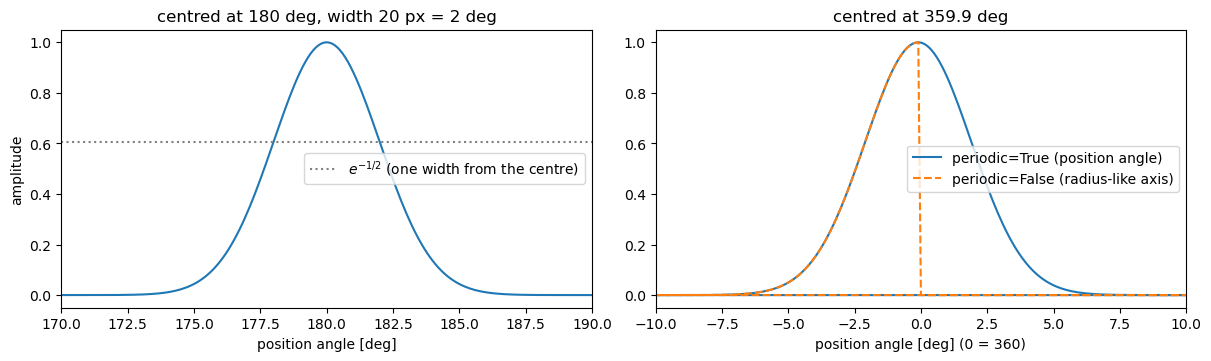

gaussian_profile: shape and wrap-around OK


In [2]:
x = np.arange(3600)
sigma = 20.0

centred = gaussian_profile(3600, 1800, sigma)                        # blob in the middle
at_edge_periodic = gaussian_profile(3600, 3599, sigma, periodic=True)  # blob at 359.9 deg, wraps
at_edge_open = gaussian_profile(3600, 3599, sigma, periodic=False)   # same blob, no wrap

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5), layout="constrained")
ax[0].plot(x * 0.1, centred)
ax[0].axhline(np.exp(-0.5), ls=":", c="gray", label=r"$e^{-1/2}$ (one width from the centre)")
ax[0].set(xlim=(170, 190), xlabel="position angle [deg]", ylabel="amplitude", title="centred at 180 deg, width 20 px = 2 deg")
ax[0].legend()

shifted = np.roll(np.arange(3600), 100)                              # show 350 deg ... 10 deg in one piece
pa = (shifted * 0.1 + 180) % 360 - 180
ax[1].plot(pa, at_edge_periodic[shifted], label="periodic=True (position angle)")
ax[1].plot(pa, at_edge_open[shifted], "--", label="periodic=False (radius-like axis)")
ax[1].set(xlim=(-10, 10), xlabel="position angle [deg] (0 = 360)", title="centred at 359.9 deg")
ax[1].legend()
plt.show()

assert np.isclose(centred.max(), 1.0) and np.isclose(centred[1800 + 20], np.exp(-0.5))
d = np.arange(1, 60)
assert np.allclose(at_edge_periodic[3599 - d], at_edge_periodic[(3599 + d) % 3600])  # symmetric across 0/360
assert at_edge_open[:60].max() < 1e-30                                              # open axis: nothing wraps
print("gaussian_profile: shape and wrap-around OK")

**Observed.** The peak is 1.000 at the centre and 0.6065 at one width, as expected. The blob centred at 359.9° is symmetric across the 0°/360° seam: values at 359.9° − d and 359.9° + d agree to round-off. The non-periodic profile is exactly zero on the other side of the edge. ✅

## 2. v2 against v3: the field stays full, from the first frame

**Change.** In v2, each blob was a rigid train of 7 copies that was never renewed. In v3, each blob is launched again every period, and it was already launching before the first frame.

**Physics.** A periodic source in a steady wind fills the whole field with a train of blobs $\lambda = vP$ apart. Once a source has run for longer than the time a launch needs to reach the top of the field, $(12L + N_r)/v \approx 200$ frames at most, the number of its launches inside the field stops changing. This is a **statistical steady state**. Every v3 source has been launching since long before frame 0 ($k < 0$), so the steady state holds from the first frame.

**Expected.**
- v2: the number of copies inside the field falls to almost zero by frame 299 (3425 → 1804 → 303 → 3 at frames 0, 100, 200, 299).
- v3: the number of launches inside the field is the same, within 5%, at **every** frame from 0 to 299. There is no spin-up.
- Both are counted the same way: centres within $4L$ of the field.


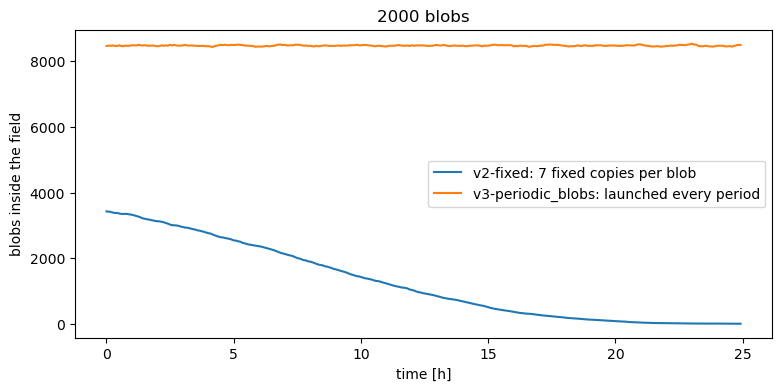

frame   0:  v2  3425   v3  8465
frame 100:  v2  1804   v3  8456
frame 150:  v2   926   v3  8479
frame 200:  v2   303   v3  8447
frame 299:  v2     3   v3  8496
v3, all 300 frames: 8435-8534 (spread 1.2%)


In [3]:
def visible_v2(t):
    """Number of v2 copies whose centre is inside the field at time step t (v2-fixed model)."""
    r_start_v2 = load_struc["outarray"][:, 0] / DR                     # v2 launch radius: 352 px (~9.9 Rsun)
    r = r_start_v2 + (t + blobs["time_0"]) * blobs["v"]               # rigid train moves outward forever
    count = 0
    for n in (0, 2, 4, 6, -2, -4, -6):                                # the 7 fixed copies
        c = r + n * blobs["period"] * blobs["v"] + n * blobs["L"]
        count += np.sum((c > -4 * blobs["L"]) & (c < NY + 4 * blobs["L"]))
    return int(count)


def visible_v3(t):
    """Number of v3 launches whose centre is inside the field at time step t (k_lo <= k <= k_hi)."""
    tau, k_lo, k_hi = launch_range(blobs, t, NY)
    count = 0
    for k in range(int(k_lo.min()), int(k_hi.max()) + 1):            # k < 0: launched before the first frame
        c = blobs["r0"] + blobs["v"] * (tau - k * blobs["period"])
        count += np.sum((k >= k_lo) & (k <= k_hi) & (c > -4 * blobs["L"]) & (c < NY + 4 * blobs["L"]))
    return int(count)


n_v2 = np.array([visible_v2(t) for t in FRAMES])
n_v3 = np.array([visible_v3(t) for t in FRAMES])

plt.figure(figsize=(9, 4))
plt.plot(FRAMES * CADENCE / 3600, n_v2, label="v2-fixed: 7 fixed copies per blob")
plt.plot(FRAMES * CADENCE / 3600, n_v3, label="v3-periodic_blobs: launched every period")
plt.xlabel("time [h]"); plt.ylabel("blobs inside the field"); plt.legend(); plt.title(f"{N_BLOBS} blobs")
plt.show()

for t in (0, 100, 150, 200, 299):
    print(f"frame {t:3d}:  v2 {n_v2[t]:5d}   v3 {n_v3[t]:5d}")

print(f"v3, all 300 frames: {n_v3.min()}-{n_v3.max()} (spread {100 * (n_v3.max() - n_v3.min()) / n_v3.mean():.1f}%)")
assert n_v2[299] < 0.01 * n_v3[299]                        # v2 has run out, v3 has not
assert n_v3.min() > 0.95 * n_v3.max()                       # v3 is in steady state from frame 0 (no spin-up)

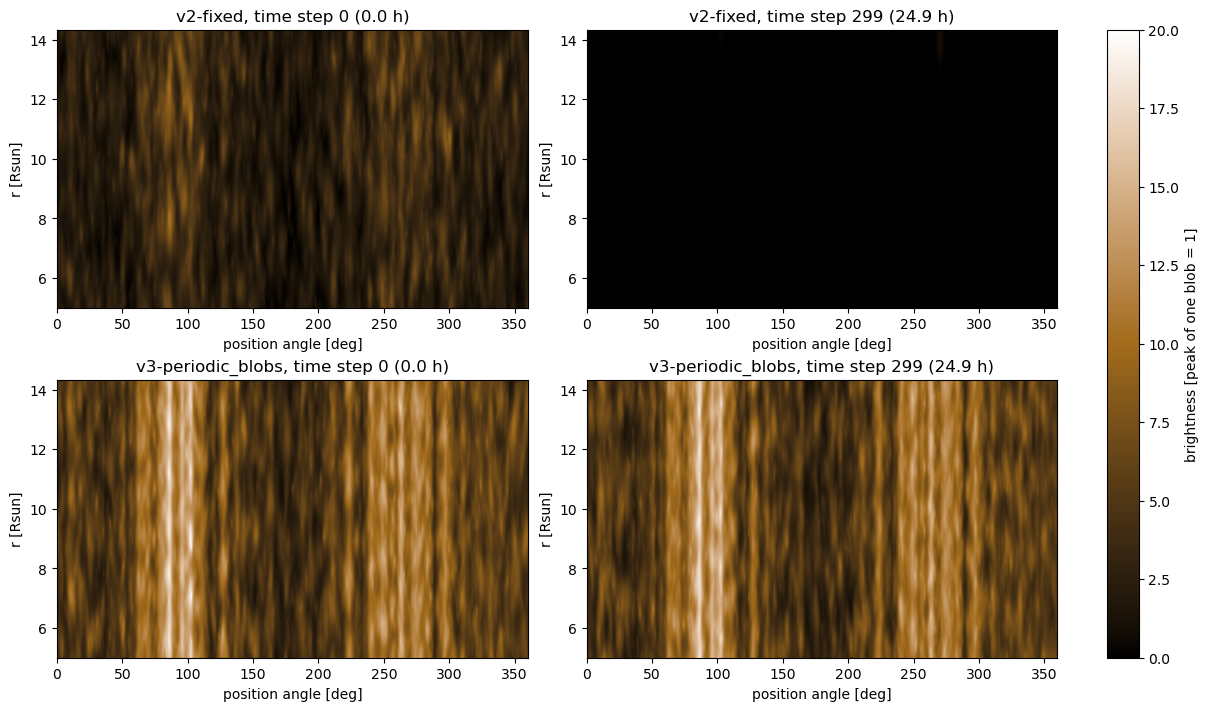

In [4]:
def frame_v2(t):
    """v2-fixed image at time step t (same formula as syncom_image in v2-fixed), for comparison."""
    r = load_struc["outarray"][:, 0] / DR + (t + blobs["time_0"]) * blobs["v"]
    gy = sum(gaussian_profile(NY, r + n * blobs["period"] * blobs["v"] + n * blobs["L"], 2 * blobs["L"])
             for n in (0, 2, 4, 6, -2, -4, -6))
    return angular_profiles(params, blobs).T @ gy

gx = angular_profiles(params, blobs)
fig, ax = plt.subplots(2, 2, figsize=(12, 7), layout="constrained")
for col, t in enumerate((0, 299)):
    for row, (name, img) in enumerate((("v2-fixed", frame_v2(t)), ("v3-periodic_blobs", syncom_image(params, blobs, t, gx=gx)))):
        im = ax[row, col].imshow(img.T, origin="lower", aspect="auto", cmap=cmap_punch, vmin=0, vmax=20,
                                 extent=[0, 360, *to_rsun([0, NY - 1])])
        ax[row, col].set(title=f"{name}, time step {t} ({t * CADENCE / 3600:.1f} h)", xlabel="position angle [deg]", ylabel="r [Rsun]")
fig.colorbar(im, ax=ax, label="brightness [peak of one blob = 1]")
plt.show()

**Observed.** | frame (time) | 0 (0 h) | 100 (8.3 h) | 150 (12.5 h) | 200 (16.7 h) | 299 (24.9 h) |
|---|---|---|---|---|---|
| v2-fixed copies in the field | 3425 | 1804 | 926 | 303 | **3** |
| v3-periodic_blobs launches in the field | **8465** | 8456 | 8479 | 8447 | **8496** |

- **v2 runs out:** by frame 299 only 3 of 14000 copies are left, and the v2 frame is black.
- **v3 is full from the first frame:** over all 300 frames the count stays between 8435 and 8534, a spread of 1.2%. There is no spin-up. The frames at time steps 0 and 299 look alike: same brightness, same structure, different blobs.
- **Why there is no spin-up:** every source has been launching since before frame 0 (launch numbers $k < 0$). At frame 0 the field already holds launches made up to $(12L + N_r)/v_{min} \approx 200$ frames earlier.
- **Slow sectors are brightest:** around 90° and 270°, launches are only $\lambda = vP \approx 1.2$–$2.3\,R_\odot$ apart and overlap more. In the fast sectors (0°, 180°) they are $2.7$–$5.4\,R_\odot$ apart. ✅

## 3. Launch behind the occulter: equal brightness at every radius

**Change.** Each blob is launched with its centre six radial widths below the bottom of the polar image: `r0 = (SYNCOM_INITIAL_R_SUN - POLAR_RHO_RANGE[0]) / SYNCOM_PIXEL - 12 L` = $-12L$ px. Before, it was launched with its centre on the bottom row ($r_0 = 0$).

**Physics.** Pixel 0 of the polar image is at 5 R☉, the occulter edge. **A blob begins from its centre, not from its edge.**
- **Launched at row 0**, a blob would appear with its inner half behind the occulter. No blob centre would ever be below row 0, so a pixel at 5 R☉ would only collect light from blobs above it. On average it would be half as bright as the rest of the field, recovering over 2–3 radial widths: $\langle I(r) \rangle / \langle I \rangle_\infty = \Phi\big((r - 5\,R_\odot)/2L\big)$, with $\Phi(0) = 1/2$. That's a dim ring about 0.8 R☉ wide around the occulter.
- **Launched $6 \times 2L$ below row 0**, its brightness at 5 R☉ at launch is $e^{-18} \approx 10^{-8}$ of its peak. It slides out from under the occulter fully formed, and every radius gets light from both sides: the brightness is the same everywhere. A real coronagraph sees the corona this way, because the occulter hides material that is already flowing outward.

**Expected.**
- `r0 = -12L` for every blob, i.e. launch heights of 1.3–4.7 R☉.
- The test blob ($L = 5$ px, $r_0 = -60$ px) is invisible at launch. Its centre crosses pixel 0 (5 R☉) $12L/v = 6$ frames later: the profile is 1 there, and $e^{-1/2} = 0.61$ one radial width ($2L$) further out.
- The mean brightness of the full run (2000 blobs, averaged over position angle and over frames 0–299) is within 5% of its mid-field value at **every** radius, from 5 R☉ to 14.3 R☉, and also within 5% in the first 10 frames alone.
- For comparison, the same blobs launched at row 0 ($r_0 = 0$) give half the brightness at 5 R☉.


r0 = r_enter - 12 L for every blob: True
launch heights: 1.26-4.66 Rsun (median 2.86); hidden for 19 frames (median)
t = 24 (launch k = 2): brightness at 5 Rsun = 3.0e-08 (hidden behind the occulter)
t = 30: brightness at 5 Rsun = 1.000, one radial width further out = 0.6065 (e^-1/2 = 0.6065)


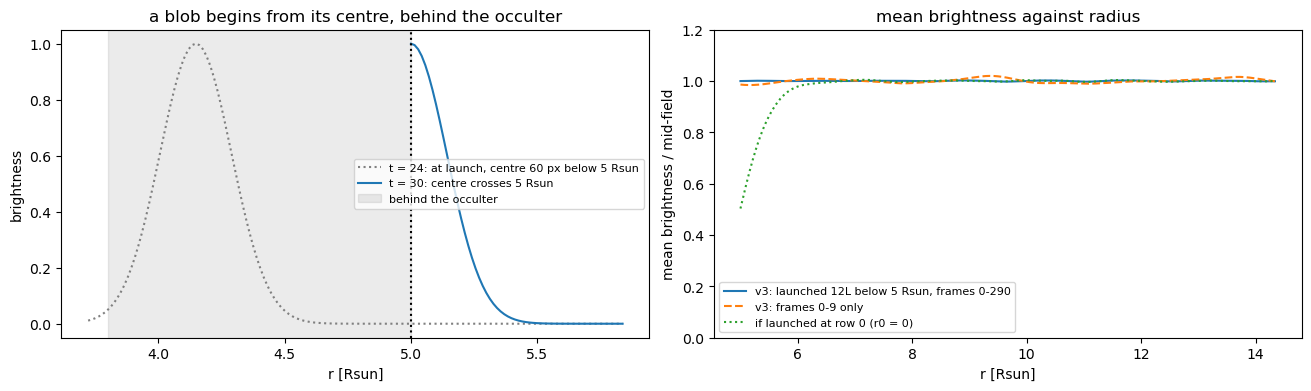

r =  5.00 Rsun: v3 1.000  (frames 0-9: 0.986)   launched at row 0: 0.503
r =  5.14 Rsun: v3 1.000  (frames 0-9: 0.984)   launched at row 0: 0.633
r =  5.28 Rsun: v3 1.001  (frames 0-9: 0.985)   launched at row 0: 0.744
r =  5.57 Rsun: v3 1.000  (frames 0-9: 0.993)   launched at row 0: 0.891
r =  9.68 Rsun: v3 0.998  (frames 0-9: 1.012)   launched at row 0: 0.999
r = 14.08 Rsun: v3 0.999  (frames 0-9: 1.007)   launched at row 0: 0.999
r = 14.34 Rsun: v3 0.999  (frames 0-9: 0.999)   launched at row 0: 1.000


In [5]:
r_enter = (params["syncom_initial_R_sun"] - POLAR_RHO_RANGE[0]) / DR              # where centres enter: pixel 0
print(f"r0 = r_enter - 12 L for every blob: {np.allclose(blobs['r0'], r_enter - 12 * blobs['L'])}")
print(f"launch heights: {to_rsun(blobs['r0']).min():.2f}-{to_rsun(blobs['r0']).max():.2f} Rsun "
      f"(median {np.median(to_rsun(blobs['r0'])):.2f}); hidden for {np.median(-blobs['r0'] / blobs['v']):.0f} frames (median)")

# One test blob at 180 deg: P = 12 frames, v = 10 px/frame, L = 5 px, time_0 = 0, launched 12 L = 60 px below 5 Rsun
one = {"psi": np.array([1800.0]), "r0": np.array([-60.0]), "v": np.array([10.0]),
       "period": np.array([12.0]), "L": np.array([5.0]), "time_0": np.array([0.0])}
one_params = dict(params, syncom_n_blobs=1)

at_launch = syncom_image(one_params, one, time_t=24)[1800]         # launch k = 2 just happened (centre at -60 px)
crossing = syncom_image(one_params, one, time_t=30)[1800]          # 6 frames later its centre is at pixel 0
two_L = int(2 * one["L"][0])
print(f"t = 24 (launch k = 2): brightness at 5 Rsun = {at_launch[0]:.1e} (hidden behind the occulter)")
print(f"t = 30: brightness at 5 Rsun = {crossing[0]:.3f}, one radial width further out = {crossing[two_L]:.4f} (e^-1/2 = {np.exp(-0.5):.4f})")

# Mean radial profile of the full run, averaged over position angle and time (gx from section 2)
def mean_profile(blob_table, steps):
    """Brightness against radius, averaged over position angle and over `steps`, divided by its mid-field value."""
    p = np.mean([syncom_image(params, blob_table, t, gx=gx).mean(axis=0) for t in steps], axis=0)
    return p / p[200:450].mean()

flat_all = mean_profile(blobs, range(0, 300, 10))                  # frames 0, 10, ..., 290
flat_first = mean_profile(blobs, range(0, 10))                     # the first 10 frames only
at_row0 = mean_profile(dict(blobs, r0=np.zeros(N_BLOBS)), range(150, 300, 10))   # same blobs launched at row 0

r = to_rsun(np.arange(NY))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), layout="constrained")
px = np.arange(-90, 60)                                               # radial pixels, also below the image
ax[0].plot(to_rsun(px), np.exp(-(px - one["r0"][0]) ** 2 / (2 * (2 * one["L"][0]) ** 2)), ":", c="gray",
           label="t = 24: at launch, centre 60 px below 5 Rsun")
ax[0].plot(r[:60], crossing[:60], label="t = 30: centre crosses 5 Rsun")
ax[0].axvline(5.0, c="k", ls=":")
ax[0].axvspan(r[0] - 1.2, 5.0, color="k", alpha=0.08, label="behind the occulter")
ax[0].set(xlabel="r [Rsun]", ylabel="brightness", title="a blob begins from its centre, behind the occulter")
ax[0].legend(fontsize=8)
ax[1].plot(r, flat_all, label="v3: launched 12L below 5 Rsun, frames 0-290")
ax[1].plot(r, flat_first, "--", label="v3: frames 0-9 only")
ax[1].plot(r, at_row0, ":", label="if launched at row 0 (r0 = 0)")
ax[1].set(ylim=(0, 1.2), xlabel="r [Rsun]", ylabel="mean brightness / mid-field", title="mean brightness against radius")
ax[1].legend(fontsize=8)
plt.show()

for x in (0, 10, 20, 40, 330, 640, 658):
    print(f"r = {r[x]:5.2f} Rsun: v3 {flat_all[x]:.3f}  (frames 0-9: {flat_first[x]:.3f})   launched at row 0: {at_row0[x]:.3f}")

assert np.allclose(blobs["r0"], r_enter - 12 * blobs["L"]) and np.isclose(to_rsun(0), 5.0)
assert at_launch[0] < 1e-7                                                                   # hidden at launch
assert np.isclose(crossing[0], 1.0) and np.isclose(crossing[two_L], np.exp(-0.5), atol=1e-6)  # centre at 5 Rsun
assert np.abs(flat_all - 1).max() < 0.05 and np.abs(flat_first - 1).max() < 0.05             # equal at every radius
assert abs(at_row0[0] - 0.5) < 0.05                                                           # the dim ring it avoids

**Observed.** - `r0 = -12L` for all 2000 blobs: launch heights 1.26–4.66 R☉ (median 2.86 R☉), and a blob stays hidden for a median of 19 frames before its centre reaches 5 R☉.
- **Test blob:** at launch ($t = 24$) its brightness at 5 R☉ is $3 \times 10^{-8}$, i.e. it is completely hidden. At $t = 30$ its centre is exactly at 5 R☉ (value 1.000) and one radial width further out the profile is 0.6065 $= e^{-1/2}$. **A blob begins from its centre, behind the occulter.**
- **Equal brightness at every radius** (mean over position angle, divided by the mid-field value):

| r [R☉] | 5.00 | 5.14 | 5.28 | 5.57 | 9.68 | 14.08 | 14.34 |
|---|---|---|---|---|---|---|---|
| v3, frames 0–290 | **1.000** | 1.000 | 1.001 | 1.000 | 0.998 | 0.999 | **0.999** |
| v3, frames 0–9 only | 0.986 | 0.984 | 0.985 | 0.993 | 1.012 | 1.007 | 0.999 |
| launched at row 0 ($r_0 = 0$) | **0.503** | 0.633 | 0.744 | 0.891 | 0.999 | 0.999 | 1.000 |

  The last row is the dim ring that launching at 5 R☉ would produce: exactly half the brightness at the occulter edge, recovering over ≈0.8 R☉, as predicted by $\Phi\big((r - 5\,R_\odot)/2L\big)$. Launching $6 \times 2L$ below removes it. The first 10 frames alone are flat to within 1.6%, the scatter expected from a finite number of blobs.
- The top row is at 14.34 R☉ (5 + 658 × 0.0141876). The plots use the same range, because `POLAR_RHO_RANGE` is computed from `SYNCOM_PIXEL`. ✅

## 4. One blob with $P$ = 1 h: it reappears every period

**Change.** This is the core of v3: a blob reappears **each time its period is up**, for the whole run.

**Physics.** With $P = 12$ frames (1 h at 300 s cadence), $v = 10$ px/frame, $L = 5$ px ($r_0 = -60$ px) and $t_0 = 0$:
- launches happen at $t = \ldots, -12, 0, 12, \ldots, 288$, hidden behind the occulter
- each launch centre crosses 5 R☉ 6 frames later: at $t = 6, 18, \ldots, 294$ (25 crossings in 300 frames)
- launches are $\lambda = vP = 120$ px apart
- each launch takes 66 frames to cross the 659 px field and then leaves

**Expected.**
- A launch centre is exactly at 5 R☉ (brightness 1 at pixel 0) at $t = 6, 18, \ldots, 294$, and at no other frame.
- At $t = 0$ the field is already full: peaks at 60, 180, 300, 420, 540 px, from launches $k = -1 \ldots -5$ made before the first frame, plus one at the top pixel (658): launch $k = -6$ has its centre at 660 px, just above the image, and its inner half still shows.
- At $t = 30$, peaks at 0, 120, 240, 360, 480, 600 px. Launch $k = 2$ is exactly at 5 R☉.
- At $t = 100$, peaks at 100, 220, 340, 460, 580 px (5 launches, 120 px apart).


In [6]:
def peaks(profile, threshold=0.5):
    """Radial pixels of the local maxima above `threshold` (including pixel 0)."""
    p = np.r_[-np.inf, profile, -np.inf]
    return [i for i in range(len(profile)) if p[i + 1] > p[i] and p[i + 1] >= p[i + 2] and profile[i] > threshold]

gx_one = angular_profiles(one_params, one)
rt_one = np.stack([syncom_image(one_params, one, t, gx=gx_one)[1800] for t in FRAMES])   # [time, radius]

crossing_frames = [t for t in FRAMES if np.isclose(rt_one[t, 0], 1.0)]    # a launch centre exactly at 5 Rsun
print("frames when a launch centre crosses 5 Rsun:", crossing_frames)
print("peaks at t = 0:  ", peaks(rt_one[0]), "(launches made before the first frame)")
print("peaks at t = 30: ", peaks(rt_one[30]))
print("peaks at t = 100:", peaks(rt_one[100]), "-> spacing", np.diff(peaks(rt_one[100])))

assert crossing_frames == list(range(6, 300, 12))                         # every period, for the whole run
assert peaks(rt_one[0]) == [60, 180, 300, 420, 540, 658]                  # already full at the first frame (k = -6 leaving at the top)
assert peaks(rt_one[30]) == [0, 120, 240, 360, 480, 600]
assert peaks(rt_one[100]) == [100, 220, 340, 460, 580]

frames when a launch centre crosses 5 Rsun: [np.int64(6), np.int64(18), np.int64(30), np.int64(42), np.int64(54), np.int64(66), np.int64(78), np.int64(90), np.int64(102), np.int64(114), np.int64(126), np.int64(138), np.int64(150), np.int64(162), np.int64(174), np.int64(186), np.int64(198), np.int64(210), np.int64(222), np.int64(234), np.int64(246), np.int64(258), np.int64(270), np.int64(282), np.int64(294)]
peaks at t = 0:   [60, 180, 300, 420, 540, 658] (launches made before the first frame)
peaks at t = 30:  [0, 120, 240, 360, 480, 600]
peaks at t = 100: [100, 220, 340, 460, 580] -> spacing [120 120 120 120]


**Observed.** - A launch centre crosses 5 R☉ at frames **6, 18, 30, …, 294: 25 crossings, exactly once per period for the whole run**. Each launch happened 6 frames earlier ($12L/v = 60/10$), hidden behind the occulter.
- At $t = 0$ the field is already full: peaks at 60, 180, 300, 420 and 540 px from launches made before the first frame, plus the top pixel (658), where launch $k = -6$ (centre at 660 px) is leaving.
- At $t = 30$ the peaks are at 0, 120, 240, 360, 480 and 600 px. Launch $k = 2$ is exactly at 5 R☉.
- At $t = 100$ the peaks are at 100, 220, 340, 460 and 580 px, spaced exactly $vP = 120$ px. ✅

## 5. Periodicity in the cube

**Physics.** A cut through the cube at one position angle, $I(\psi_0, r, t)$, is a **radius–time diagram**.
- Each launch of a blob draws a straight line $r = 5\,R_\odot + \Delta r\,[\,r_0 + v\,(\tau - kP)\,]$. Its slope is the speed. Lines enter at 5 R☉ from below, because launches start behind the occulter.
- Successive launches of the same blob are parallel lines, one period $P$ apart in time.
- At a fixed radius, the brightness repeats every $P$, so its autocorrelation has a peak at lag $P$.

This is the signal that time-delay correlation and FlowTrack use to measure speeds.

The function below draws the diagram, overlays the tracks predicted from the blob table, and plots the light curve at one radius together with its autocorrelation.

It's applied to three cases of increasing complexity:
- **5a.** One blob alone: periodicity is exact.
- **5b.** A sparse run (40 blobs): one blob dominates its position angle.
- **5c.** The full run (2000 blobs): many overlapping trains, from which the wind speed is recovered.


In [7]:
def radial_time_slice(params, blobs, psi_index, steps):
    """
    Radius-time diagram I(psi_index, r, t) of a SynCOM run, computed directly from the model.

    Only the blobs that are bright at this position angle are used (angular weight > 1e-6 of
    their peak), which gives the same column as the full image but is much faster than
    building all 3600 position angles.

    Parameters:
        params: SynCOM parameter dict
        blobs: blob table (syncom_blob_table)
        psi_index: position-angle pixel (0.1 deg each)
        steps: time steps [frames]

    Returns:
        np.ndarray [len(steps), NY]: brightness against time (rows) and radius (columns)
    """
    weight = angular_profiles(params, blobs)[:, psi_index]          # how much each blob shows at psi_index
    near = weight > 1e-6
    sub = {key: values[near] for key, values in blobs.items()}       # blobs that matter here
    sub_params = dict(params, syncom_n_blobs=int(near.sum()))
    gx = angular_profiles(sub_params, sub)
    return np.stack([syncom_image(sub_params, sub, t, gx=gx)[psi_index] for t in steps])


def radial_time_slice_from_fits(fits_dir, run_name, steps, psi_index):
    """Same diagram read from FITS frames written by write_fits_frames (image shape (NY, NX))."""
    return np.stack([fits.getdata(Path(fits_dir) / f"{run_name}_{t:04d}.fts")[:, psi_index] for t in steps])


def autocorrelation(series):
    """Normalised autocorrelation of a time series (lag 0 = 1), for lags 0 ... len-1."""
    s = series - series.mean()
    ac = np.correlate(s, s, mode="full")[len(s) - 1:]
    return ac / ac[0]


def plot_radial_time_slice(rt, steps, title, blob=None, r_probe=300, cadence=CADENCE):
    """
    Plot a radius-time diagram, the light curve at one radius and its autocorrelation.

    Parameters:
        rt: [len(steps), NY] diagram (radial_time_slice or radial_time_slice_from_fits)
        steps: time steps of the rows of rt [frames]
        title: figure title
        blob: optional dict with this blob's 'v', 'period', 'r0', 'time_0' (scalars) -> its
              predicted launch tracks r = r0 + v (tau - k P) are drawn as dashed lines,
              and lag P is marked on the autocorrelation
        r_probe: radial pixel of the light curve
    Returns:
        lag_of_peak: lag [frames] of the highest autocorrelation peak after lag 0
    """
    hours = np.asarray(steps) * cadence / 3600
    fig, ax = plt.subplots(1, 3, figsize=(15, 4), layout="constrained", gridspec_kw={"width_ratios": [2, 1.3, 1]})

    # (a) radius-time diagram
    ax[0].imshow(rt.T, origin="lower", aspect="auto", cmap=cmap_punch,
                 extent=[hours[0], hours[-1], *to_rsun([0, rt.shape[1] - 1])])
    if blob is not None:                                       # predicted tracks of every launch k
        tau = np.asarray(steps) + blob["time_0"]
        k_first = int(np.floor((blob["r0"] + blob["v"] * tau.min() - rt.shape[1]) / (blob["v"] * blob["period"])))
        for k in range(k_first, int(tau.max() // blob["period"]) + 1):    # k < 0: launched before the first step
            r = blob["r0"] + blob["v"] * (tau - k * blob["period"])
            ok = (tau >= k * blob["period"]) & (r >= 0) & (r <= rt.shape[1] - 1)
            ax[0].plot(hours[ok], to_rsun(r[ok]), "w--", lw=0.8)
    ax[0].axhline(to_rsun(r_probe), c="c", lw=0.8)
    ax[0].set(xlabel="time [h]", ylabel="r [Rsun]", title="radius-time diagram (dashed: predicted launches)")

    # (b) light curve at r_probe
    curve = rt[:, r_probe]
    ax[1].plot(hours, curve)
    ax[1].set(xlabel="time [h]", ylabel="brightness", title=f"light curve at r = {to_rsun(r_probe):.2f} Rsun")

    # (c) autocorrelation of the light curve
    ac = autocorrelation(curve)
    lags = np.arange(len(ac))
    is_peak = (ac[1:-1] > ac[:-2]) & (ac[1:-1] >= ac[2:])
    peak_lags = lags[1:-1][is_peak]
    lag_of_peak = int(peak_lags[np.argmax(ac[1:-1][is_peak])]) if is_peak.any() else None
    ax[2].plot(lags * cadence / 3600, ac)
    if blob is not None:
        ax[2].axvline(blob["period"] * cadence / 3600, c="r", ls="--", label=f"P = {blob['period'] * cadence / 3600:.2f} h")
        ax[2].legend()
    ax[2].set(xlim=(0, 4 * (blob["period"] if blob else 12) * cadence / 3600), xlabel="lag [h]", title="autocorrelation")

    fig.suptitle(title)
    plt.show()
    return lag_of_peak

### 5a. The single test blob ($P$ = 1 h, $v$ = 10 px/frame)

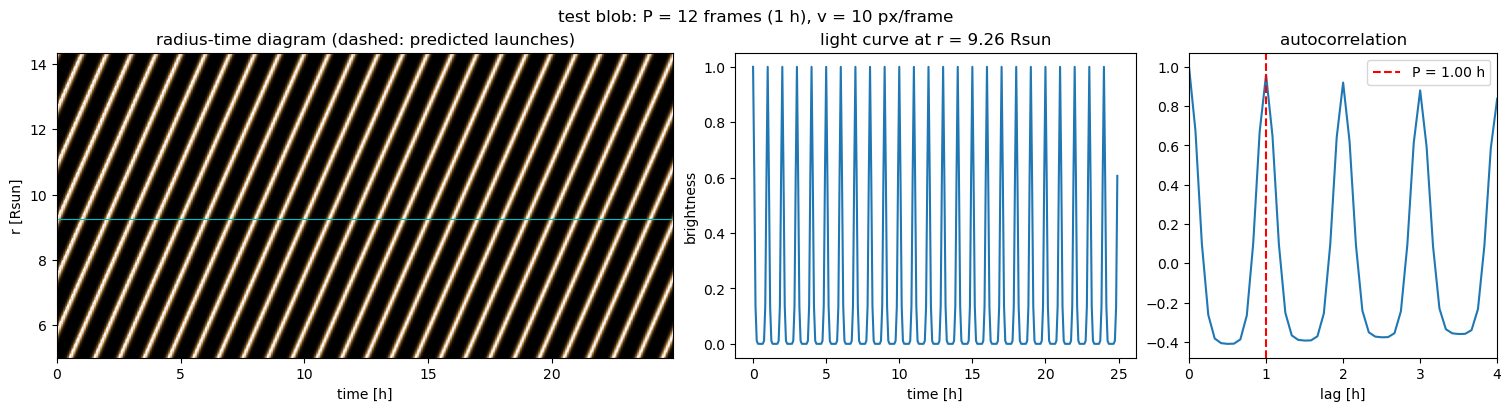

autocorrelation peak at lag 12 frames


In [8]:
lag = plot_radial_time_slice(rt_one, FRAMES, "test blob: P = 12 frames (1 h), v = 10 px/frame",
                             blob={k: v[0] for k, v in one.items()})
print("autocorrelation peak at lag", lag, "frames")
assert lag == 12

### 5b. A sparse run: 40 blobs, the same model
With few blobs, each position angle is dominated by a single blob, so its own periodicity can be read off the cube. This run uses exactly the same functions (`syncom_load` → `syncom_blob_table` → `syncom_image`) with `SYNCOM_N_BLOBS=40`. The cell picks the most isolated blob.

**Expected.** Streaks on the predicted tracks, and an autocorrelation peak at the blob's period $P$. $P$ isn't a whole number of frames and the light curve is sampled once per frame, so the peak can fall up to about one frame from $P$. The test allows ±1.5 frames.


No file or date entered. Using default: syncom_20140414_densfix.sav


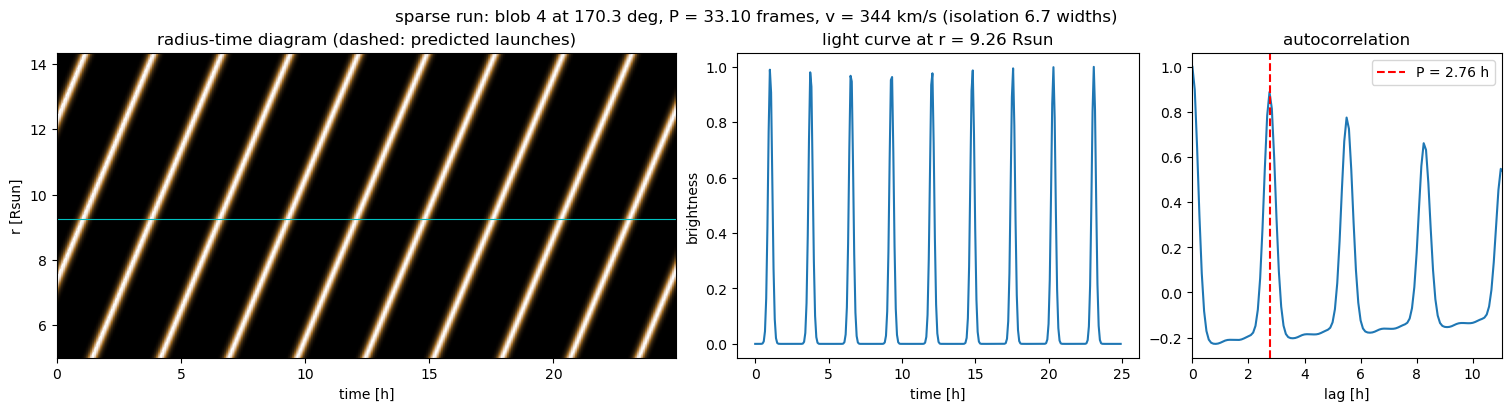

P = 33.10 frames, autocorrelation peak at lag 33 frames


In [9]:
params_40 = default_syncom_prams(SYNCOM_N_BLOBS=40, SYNCOM_SCALE_FACTOR=SCALE)
blobs_40 = syncom_blob_table(params_40, syncom_load(params_40, simple=True), SCALE)

def isolation(blob_table, i):
    """Gap between blob i and its nearest neighbour, in units of their summed widths (> 3: well separated)."""
    psi, L = blob_table["psi"], blob_table["L"]
    others = np.delete(np.arange(len(psi)), i)
    gap = np.abs((psi[others] - psi[i] + 1800) % 3600 - 1800)        # angular distance on the circle [px]
    return np.min(gap / (L[others] + L[i]))

i40 = max(range(40), key=lambda i: isolation(blobs_40, i))
b40 = {k: v[i40] for k, v in blobs_40.items()}
rt_40 = radial_time_slice(params_40, blobs_40, int(b40["psi"]), FRAMES)
lag_40 = plot_radial_time_slice(rt_40, FRAMES, f"sparse run: blob {i40} at {b40['psi'] / 10:.1f} deg, "
                                f"P = {b40['period']:.2f} frames, v = {b40['v'] * DR * 696000 / CADENCE:.0f} km/s "
                                f"(isolation {isolation(blobs_40, i40):.1f} widths)", blob=b40)
print(f"P = {b40['period']:.2f} frames, autocorrelation peak at lag {lag_40} frames")
assert abs(lag_40 - b40["period"]) <= 1.5

### 5c. The full run (2000 blobs): many overlapping trains, one wind speed
With 2000 blobs, **50–80 blobs overlap at every position angle**. Blobs are on average 0.18° apart but up to 2.2° wide. The light curve at one angle is a sum of dozens of periodic sources with periods from 18 to 36 frames. Its autocorrelation has peaks at many of these periods, so the period of a single blob can't be read from it. The plot marks the periods of the strongest contributors.

What does survive the overlap is the **speed**. The wind speed depends only on position angle, and it changes by only about 2 km/s per degree, so all the overlapping blobs move at nearly the same speed. A brightness pattern seen at $r_1$ reaches $r_2$ a time

$$\Delta t = \frac{r_2 - r_1}{v}$$

later, so the cross-correlation of the two light curves peaks at that lag. This is the time-delay correlation method.

**Expected.** In both sectors, the speed recovered from the cross-correlation lag between $r_1 = 150$ px and $r_2 = 450$ px agrees with the input speed $v(\psi)$ to within 5%. The fast sector ($\psi \approx 180^\circ$) gives about twice the speed of the slow sector ($\psi \approx 90^\circ$).


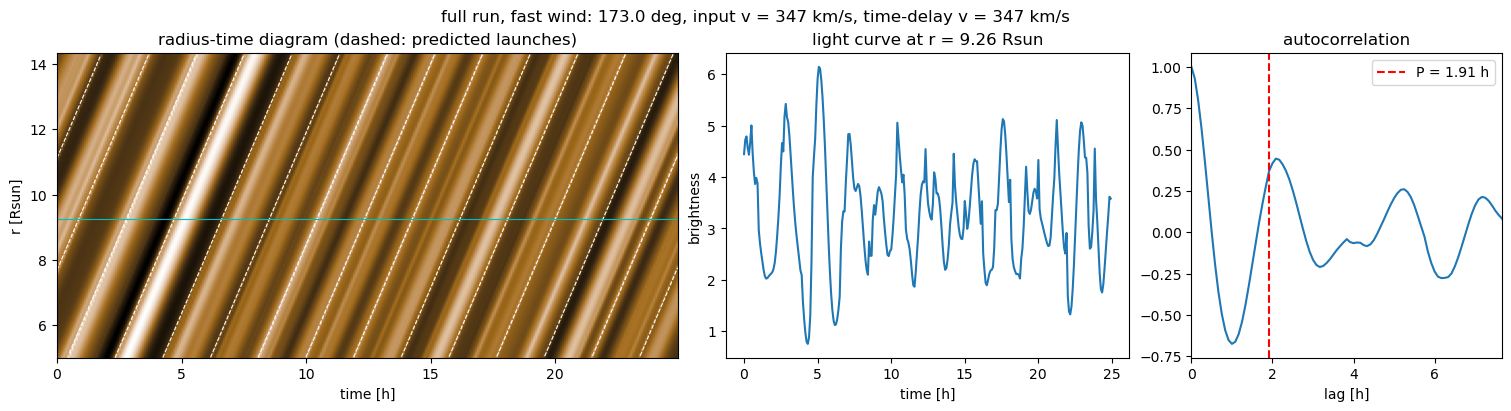

fast wind: 51 blobs contribute at 173.0 deg; strongest periods [23.  25.4 21.3 21.2 24.9] frames (weights [1.   0.97 0.96 0.93 0.75])
   input v = 347.0 km/s, time-delay v = 347.1 km/s (+0.0%)


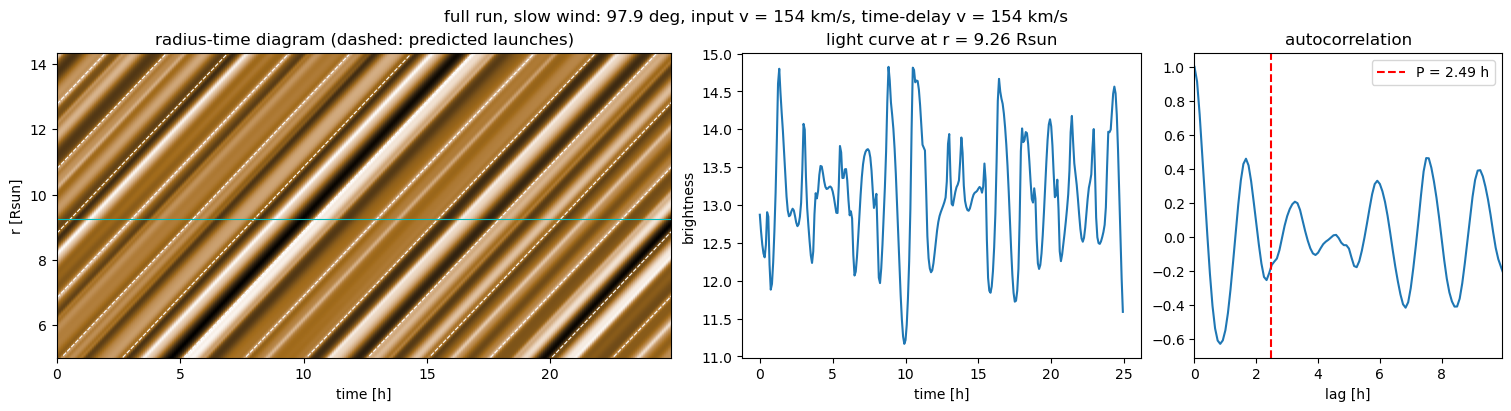

slow wind: 83 blobs contribute at 97.9 deg; strongest periods [29.8 21.4 33.3 22.4 22.8] frames (weights [1.   0.98 0.98 0.97 0.97])
   input v = 153.8 km/s, time-delay v = 154.1 km/s (+0.2%)


In [10]:
def delay_speed(rt, r1, r2, max_lag=150):
    """
    Speed [px/frame] from the time delay between the light curves at radial pixels r1 < r2.
    The lag of the cross-correlation peak is refined to sub-frame precision with a parabola
    through the peak and its two neighbours.
    """
    a = rt[:, r1] - rt[:, r1].mean()
    b = rt[:, r2] - rt[:, r2].mean()
    lags = np.arange(1, max_lag)
    cc = np.array([np.sum(a[:-lag] * b[lag:]) for lag in lags])      # b later than a by `lag` frames
    k = np.argmax(cc)
    shift = 0.5 * (cc[k - 1] - cc[k + 1]) / (cc[k - 1] - 2 * cc[k] + cc[k + 1])
    return (r2 - r1) / (lags[k] + shift)

def most_isolated_near(target_deg, window_deg=10):
    """Blob of the full run within +-window_deg of target_deg with the largest gap to its neighbours."""
    d = np.abs((blobs["psi"] - target_deg * 10 + 1800) % 3600 - 1800)
    return max(np.where(d <= window_deg * 10)[0], key=lambda i: isolation(blobs, i))

speeds = {}
for name, target in (("fast wind", 180), ("slow wind", 90)):
    i = most_isolated_near(target)
    b = {k: v[i] for k, v in blobs.items()}
    rt = radial_time_slice(params, blobs, int(b["psi"]), FRAMES)
    v_true = b["v"] * DR * 696000 / CADENCE                       # input speed at this position angle [km/s]
    v_meas = delay_speed(rt, 150, 450) * DR * 696000 / CADENCE     # speed recovered from the cube [km/s]
    speeds[name] = (v_true, v_meas)

    plot_radial_time_slice(rt, FRAMES, f"full run, {name}: {b['psi'] / 10:.1f} deg, input v = {v_true:.0f} km/s, "
                           f"time-delay v = {v_meas:.0f} km/s", blob=b)
    weight = angular_profiles(params, blobs)[:, int(b["psi"])]
    strong = np.argsort(weight)[::-1][:5]
    print(f"{name}: {np.sum(weight > 1e-6)} blobs contribute at {b['psi'] / 10:.1f} deg; strongest periods "
          f"{np.round(blobs['period'][strong], 1)} frames (weights {np.round(weight[strong], 2)})")
    print(f"   input v = {v_true:.1f} km/s, time-delay v = {v_meas:.1f} km/s ({100 * (v_meas / v_true - 1):+.1f}%)")

for name, (v_true, v_meas) in speeds.items():
    assert abs(v_meas / v_true - 1) < 0.05, (name, v_true, v_meas)
assert speeds["fast wind"][1] > 1.8 * speeds["slow wind"][1]

**Observed.** - **5a. One blob:** the autocorrelation peaks at exactly 12 frames (= $P$). The radius–time diagram shows parallel streaks on the predicted centre tracks for the whole run, including at $t = 0$, where launches made before the first frame are already in the field.
- **5b. Sparse run:** blob 4 at 170.3° ($P$ = 33.10 frames = 2.76 h, $v$ = 344 km/s, 6.7 widths from its nearest neighbour).
  - Nine parallel streaks on the predicted tracks. At $t = 0$ the first streak is already at ≈12 R☉.
  - The light curve shows one pulse per period, all of the same height.
  - The autocorrelation peaks at 33 frames and at its multiples.
- **5c. Full run:** 51 blobs (at 173.0°) and 83 blobs (at 97.9°) contribute.
  - The autocorrelation shows several peaks, because periods of 21–33 frames are mixed together, so no single period dominates. This is the expected result of overlap, not an error; section 6 extracts the frequencies with the Fourier power spectrum instead.
  - The streaks all have the same slope, and the speed recovered by time-delay correlation matches the input:

| sector | input $v(\psi)$ | time-delay speed from the cube | error |
|---|---|---|---|
| fast wind (173.0°) | 347.0 km/s | 347.1 km/s | +0.0% |
| slow wind (97.9°) | 153.8 km/s | 154.1 km/s | +0.2% |

- Compared with the earlier v3 (launch at 5 R☉), the diagrams have **no dark wedge** at the start (no spin-up) and **no dark band along 5 R☉** (blobs enter fully formed). ✅

## 6. Frequencies in the images against `syncom_load`: the Fourier power spectrum

**Question.** `syncom_load` gives every 0.1° position-angle bin a period $P$, drawn uniformly between 1.5 and 3 h (18–36 frames), and every blob takes the period of its bin. Are these the frequencies that actually appear in the images? And what is the best tool to extract them?

**Physics: the spectrum of a blob train.** At a fixed radius, one blob produces a train of Gaussian pulses in time: one pulse per launch, every $P$ frames. Each pulse lasts $\sigma_t = 2L/v$ frames (the radial width divided by the speed). A periodic train of Gaussian pulses has the Fourier series

$$
s(t) = \frac{\sigma_t\sqrt{2\pi}}{P}\left[1 + 2\sum_{n \ge 1} e^{-2\pi^2 n^2 \sigma_t^2 / P^2}\cos\!\left(\frac{2\pi n\,(t - t_0)}{P}\right)\right],
$$

so its Fourier power spectrum is a set of **lines** at the frequency $f = 1/P$ and its harmonics $n/P$. Short pulses (small $\sigma_t/P$) have strong harmonics, and long pulses have almost only the fundamental. The image is a sum over blobs, each weighted by its angular profile $w_b(\psi)$. Blobs have different periods, so in a long record their cross terms average out and their **powers add**: the spectrum at angle $\psi$ is the sum of every contributing blob's lines.

**Resolution.** A record of length $T$ resolves frequencies $\Delta f = 1/T$ apart (the Rayleigh criterion). The run lasts $T = 300$ frames (25 h), so $\Delta f = 1/300$ per frame (0.011 mHz). The `syncom_load` band $1/36$ to $1/18$ per frame (0.093–0.185 mHz) is only about 8 resolution elements wide. With 50–80 blobs overlapping at each position angle (section 5c), several blobs share each resolution element, so the period of one blob can be read off only where that blob dominates its angle.

**Choosing the tool.**

| tool | how it finds a period | verdict for SynCOM |
|---|---|---|
| autocorrelation | first strong peak in lag | finds one period; a sum of sources gives a mixture of peaks (section 5c). Precision limited to about 0.04 frames |
| Lomb–Scargle periodogram | least-squares sine fit at each trial frequency | designed for uneven sampling. The frames are evenly spaced, so it reduces to the Fourier power spectrum |
| wavelet transform | power against time and frequency | for periods that change with time. SynCOM periods are constant, so it only loses frequency resolution |
| **Fourier power spectrum** $\lvert\mathrm{DFT}\rvert^2$ **with Hann window, zero padding and peak interpolation** | power at every frequency | **chosen**: separates superposed sources into separate lines, the powers add, so the whole spectrum can be **predicted from `syncom_load`** and compared, and it is the most precise |

The Hann window suppresses leakage from strong lines into weak ones. Zero padding (to 8192 points) samples the spectrum finely, and a parabola through the three highest points gives the peak to a fraction of a resolution element. All of this needs a **stationary** record, and v3 is in steady state from frame 0 (section 2), so the whole 300-frame run can be used.

**Expected.**
- **6a. Dominant blobs (sparse 40-blob run):** for each blob that makes at least 95% of the light at its own position angle, the Fourier power spectrum of the light curve there peaks at its `syncom_load` period to within 0.1 frame. The tools are compared on the same blobs.
- **6b. The full run (2000 blobs):** the mean Fourier power spectrum over all 3600 position angles matches the spectrum predicted from the `syncom_load` periods, speeds and sizes, in shape (correlation > 0.98) and in absolute power (within 10%). Scaling every period by a factor $s$ and repeating the comparison gives the best match at $s = 1$ (within 1%). So the frequencies in the images are the ones in `syncom_load`.


sparse run: 16 of 40 blobs make at least 95% of the light at their own position angle
tool                                                    dominant blobs within 0.1 frame   median |error| [frames]   all 40 within 0.5 frame
Fourier power spectrum (Hann, zero padding, parabola)    16 / 16                    0.001                    31 / 40
Lomb-Scargle                                             16 / 16                    0.009                    32 / 40
autocorrelation                                          15 / 16                    0.037                    34 / 40


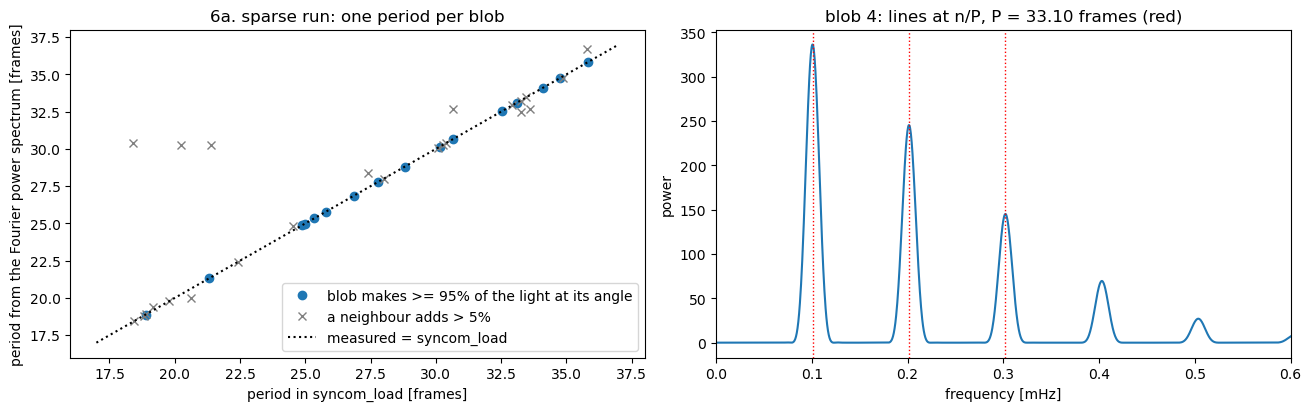

In [11]:
T = len(FRAMES)
NFFT = 8192                                    # zero padding: spectrum sampled every 1/8192 per frame
freq = np.fft.rfftfreq(NFFT)                   # [cycles per frame]; mHz = freq / CADENCE * 1e3
hann = np.hanning(T)


def fourier_power_spectrum(series):
    """Fourier power spectrum |DFT|^2 of a light curve (mean removed, Hann window, zero padded to NFFT)."""
    return np.abs(np.fft.rfft((series - series.mean()) * hann, n=NFFT)) ** 2


def peak_period(power, p_min=15, p_max=45):
    """
    Period [frames] of the highest Fourier-power peak with p_min < P < p_max, refined by a parabola
    through the log-power of the peak and its two neighbours (sub-resolution precision).
    """
    band = (freq > 1 / p_max) & (freq < 1 / p_min)
    k = np.argmax(np.where(band, power, 0))
    y0, y1, y2 = np.log(power[k - 1:k + 2])
    return NFFT / (k + 0.5 * (y0 - y2) / (y0 - 2 * y1 + y2))


def acf_period(series, p_min=15, p_max=45):
    """Period [frames] from the highest autocorrelation peak with p_min < lag < p_max (parabola-refined)."""
    ac = autocorrelation(series)
    k = p_min + np.argmax(ac[p_min:p_max + 1])
    y0, y1, y2 = ac[k - 1:k + 2]
    return k + 0.5 * (y0 - y2) / (y0 - 2 * y1 + y2)


def lomb_scargle_period(series, p_min=15, p_max=45):
    """Period [frames] of the highest Lomb-Scargle peak on a fine frequency grid."""
    from astropy.timeseries import LombScargle
    trial = np.linspace(1 / p_max, 1 / p_min, 4000)
    return 1 / trial[np.argmax(LombScargle(np.arange(T), series).power(trial))]


# 6a. Sparse run: light curve of every blob at its own position angle, at r = 300 px
R_PROBE = 300
gx_40 = angular_profiles(params_40, blobs_40)
lc_40 = np.stack([syncom_image(params_40, blobs_40, t, gx=gx_40)[:, R_PROBE] for t in FRAMES])      # [time, psi]
# Share of the light at blob i's own position angle that comes from blob i (1 = alone there)
own_share = np.array([gx_40[i, int(blobs_40["psi"][i])] / gx_40[:, int(blobs_40["psi"][i])].sum() for i in range(40)])
isolated = own_share >= 0.95                                           # the blob dominates its position angle

tools = {"Fourier power spectrum (Hann, zero padding, parabola)": lambda x: peak_period(fourier_power_spectrum(x)),
         "Lomb-Scargle": lomb_scargle_period,
         "autocorrelation": acf_period}
errors = {name: np.array([tool(lc_40[:, int(blobs_40["psi"][i])]) - blobs_40["period"][i] for i in range(40)])
          for name, tool in tools.items()}

print(f"sparse run: {isolated.sum()} of 40 blobs make at least 95% of the light at their own position angle")
print(f"{'tool':55s} dominant blobs within 0.1 frame   median |error| [frames]   all 40 within 0.5 frame")
for name, err in errors.items():
    print(f"{name:55s} {np.sum(np.abs(err[isolated]) < 0.1):3d} / {isolated.sum()}"
          f"                    {np.median(np.abs(err[isolated])):.3f}                   {np.sum(np.abs(err) < 0.5):3d} / 40")

best = errors["Fourier power spectrum (Hann, zero padding, parabola)"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4), layout="constrained")
ax[0].plot(blobs_40["period"][isolated], (blobs_40["period"] + best)[isolated], "o", label="blob makes >= 95% of the light at its angle")
ax[0].plot(blobs_40["period"][~isolated], (blobs_40["period"] + best)[~isolated], "x", c="gray", label="a neighbour adds > 5%")
ax[0].plot([17, 37], [17, 37], "k:", label="measured = syncom_load")
ax[0].set(xlabel="period in syncom_load [frames]", ylabel="period from the Fourier power spectrum [frames]", title="6a. sparse run: one period per blob")
ax[0].legend()
i_show = int(np.argmax(own_share * (blobs_40["L"] > 5)))                # a dominant blob with visible harmonics
ax[1].plot(freq / CADENCE * 1e3, fourier_power_spectrum(lc_40[:, int(blobs_40["psi"][i_show])]))
for n in (1, 2, 3):
    ax[1].axvline(n / blobs_40["period"][i_show] / CADENCE * 1e3, c="r", ls=":", lw=1)
ax[1].set(xlim=(0, 0.6), xlabel="frequency [mHz]", ylabel="power",
          title=f"blob {i_show}: lines at n/P, P = {blobs_40['period'][i_show]:.2f} frames (red)")
plt.show()

assert np.all(np.abs(best[isolated]) < 0.1)                                      # dominant blobs: exact periods

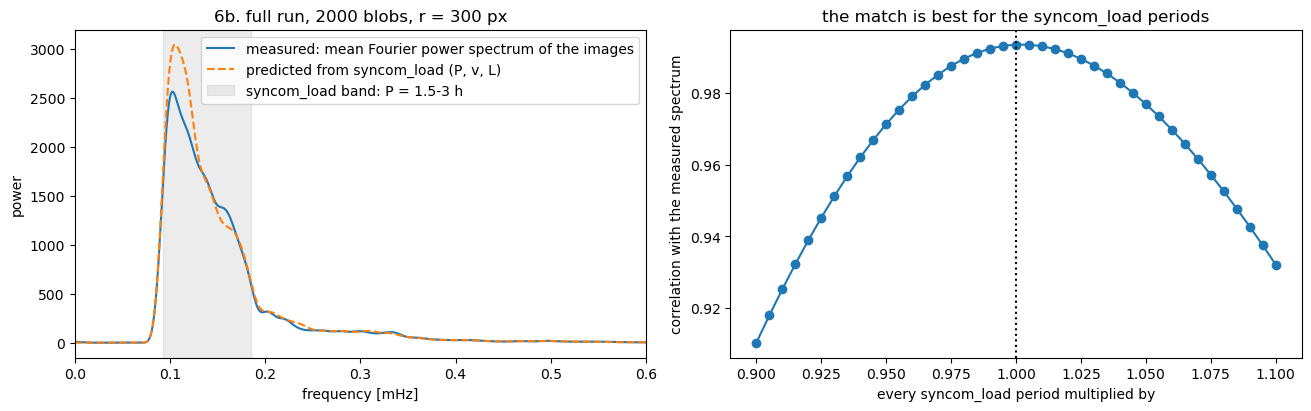

measured vs predicted: correlation 0.9935, total power ratio 0.931
best period scale 1.000; correlation at 0.95 / 1.00 / 1.05: 0.9713 / 0.9935 / 0.9769


In [12]:
# 6b. Full run: light curves at r = 300 px for all 3600 position angles, 300 frames
lc = np.stack([syncom_image(params, blobs, t, gx=gx)[:, R_PROBE] for t in FRAMES])     # [time, psi]
measured = np.mean([fourier_power_spectrum(lc[:, psi]) for psi in range(NX)], axis=0)              # mean over position angle


def predicted_spectrum(period_scale=1.0, n_harmonics=7):
    """
    Mean Fourier power spectrum predicted from the blob table alone (no images): every blob b adds lines at
    n / P_b with cosine amplitude a_bn = 2 (sigma_t sqrt(2 pi) / P) exp(-2 pi^2 n^2 sigma_t^2 / P^2),
    sigma_t = 2 L / v, weighted by sum_psi w_b(psi)^2 (its angular profile), and each line is
    spread by the Hann window response |W(f)|^2. A cosine of amplitude a has power (a / 2)^2 |W|^2.
    period_scale multiplies every period (a control: the match should be best at 1).
    """
    period = blobs["period"] * period_scale
    sigma_t = 2 * blobs["L"] / blobs["v"]
    n = np.arange(1, n_harmonics + 1)[:, None]
    amplitude = 2 * sigma_t * np.sqrt(2 * np.pi) / period * np.exp(-2 * np.pi ** 2 * n ** 2 * sigma_t ** 2 / period ** 2)
    weight = (gx ** 2).sum(axis=1)                                                   # sum over psi of w_b(psi)^2
    df = np.arange(-0.03, 0.03, 0.25 / NFFT)                                         # window response |W(df)|^2
    window_power = np.abs(np.exp(-2j * np.pi * df[:, None] * np.arange(T)) @ hann) ** 2
    spectrum = np.zeros_like(freq)
    for f_line, power in zip((n / period).ravel(), ((amplitude / 2) ** 2 * weight).ravel()):
        spectrum += power * np.interp(freq - f_line, df, window_power, left=0, right=0)
    return spectrum / NX


band = (freq > 0.01) & (freq < 0.2)                                                  # periods 5-100 frames
prediction = predicted_spectrum()
corr = np.corrcoef(measured[band], prediction[band])[0, 1]
ratio = measured[band].sum() / prediction[band].sum()
scales = np.round(np.arange(0.90, 1.101, 0.005), 3)
scan = np.array([np.corrcoef(measured[band], predicted_spectrum(s)[band])[0, 1] for s in scales])

fig, ax = plt.subplots(1, 2, figsize=(13, 4), layout="constrained")
mhz = freq / CADENCE * 1e3
ax[0].plot(mhz, measured, label="measured: mean Fourier power spectrum of the images")
ax[0].plot(mhz, prediction, "--", label="predicted from syncom_load (P, v, L)")
ax[0].axvspan(1 / 36 / CADENCE * 1e3, 1 / 18 / CADENCE * 1e3, color="gray", alpha=0.15, label="syncom_load band: P = 1.5-3 h")
ax[0].set(xlim=(0, 0.6), xlabel="frequency [mHz]", ylabel="power", title="6b. full run, 2000 blobs, r = 300 px")
ax[0].legend()
ax[1].plot(scales, scan, "o-")
ax[1].axvline(1.0, c="k", ls=":")
ax[1].set(xlabel="every syncom_load period multiplied by", ylabel="correlation with the measured spectrum",
          title="the match is best for the syncom_load periods")
plt.show()

print(f"measured vs predicted: correlation {corr:.4f}, total power ratio {ratio:.3f}")
print(f"best period scale {scales[np.argmax(scan)]:.3f}; correlation at 0.95 / 1.00 / 1.05: "
      f"{scan[scales == 0.95][0]:.4f} / {scan[scales == 1.0][0]:.4f} / {scan[scales == 1.05][0]:.4f}")
assert corr > 0.98 and abs(ratio - 1) < 0.10
assert abs(scales[np.argmax(scan)] - 1) <= 0.01

**Observed.** - **6a. Choosing the tool (sparse run).** 16 of the 40 blobs make at least 95% of the light at their own position angle:

| tool | dominant blobs within 0.1 frame of the `syncom_load` period | median error | all 40 blobs within 0.5 frame |
|---|---|---|---|
| **Fourier power spectrum** (Hann window, zero padding, parabola) | **16 / 16** | **0.001 frames** | 31 / 40 |
| Lomb–Scargle | 16 / 16 | 0.009 frames | 32 / 40 |
| autocorrelation | 15 / 16 | 0.037 frames | 34 / 40 |

  The Fourier power spectrum is the most precise: 0.001 frames is 0.3 s on a period of hours. Its spectrum shows the expected lines at $n/P$, getting weaker with $n$ as $e^{-2\pi^2 n^2 \sigma_t^2/P^2}$. The blobs it misses are those where a neighbour adds more than 5% of the light: several are pulled to the same neighbour's period (≈30.3 frames). No tool can assign a period to a blob that doesn't dominate its own light curve.
- **6b. Full run (2000 blobs).** The mean Fourier power spectrum over all 3600 position angles agrees with the spectrum predicted from the `syncom_load` periods, speeds and sizes alone:
  - shape: correlation **0.9935**
  - power: the measured total is 7% below the prediction (ratio 0.931), mostly at the strongest peak near 0.1 mHz. The cause wasn't investigated; it doesn't move the frequencies.
  - frequency: scaling every `syncom_load` period by $s$ gives the best match at **$s = 1.000$**. The correlation drops to 0.971 at $s = 0.95$ and 0.977 at $s = 1.05$.
  - 82% of the power lies in the `syncom_load` band $P$ = 1.5–3 h (0.093–0.185 mHz). The rest is the harmonics $n/P$ of short pulses.

**So the frequencies in the images are the ones put in by `syncom_load`.** The best tool to extract them is the Fourier power spectrum. With heavy overlap it gives the population of periods rather than one period per position angle. ✅

### 6c. The run of the main notebook: `SynCOM_v3.1-periodic_blobs_N_BLOBS_10000_SCALE_FACTOR_1.0`

**Question.** The main notebook runs 5 times more blobs than the reference run of 6b, each half as wide (10000 blobs, scale factor 1, 500 frames). Does that make the periods easier to read?

**Physics: how much the blobs overlap.** The light at one position angle is a sum over blobs weighted by their angular profiles $w_b(\psi)$. A useful measure of how many blobs share that light is the **effective number**

$$
N_\text{eff}(\psi) = \frac{\left(\sum_b w_b(\psi)\right)^2}{\sum_b w_b(\psi)^2},
$$

which is 1 when one blob makes all the light and $n$ when $n$ blobs contribute equally. The blobs are spread uniformly in angle, so $N_\text{eff} \propto N \langle L \rangle$: the number of blobs per degree times their width. Going from 2000 blobs at scale 2 to 10000 blobs at scale 1 multiplies $N \langle L \rangle$ by $5 / 2 = 2.5$. **Smaller blobs, but many more of them, means more overlap, not less.**

**Physics: frequency resolution.** 500 frames resolve frequencies $1/500$ per frame apart, instead of $1/300$. The `syncom_load` band (1/36 to 1/18 per frame) then spans about 14 resolution elements instead of 8. That helps separate lines, but only if there are fewer lines than resolution elements at each angle.

**Expected.**
- $N_\text{eff}$ about 2.5 times larger than in the 2000-blob run, and no blob that makes 95% of the light at its own angle.
- The strongest line at one angle matches the strongest line predicted there no more often than in the 2000-blob run: one period per angle can't be read.
- The **population** of periods is still exactly the `syncom_load` one, and better measured, because 10000 blobs sample the period distribution more densely: correlation > 0.98 between the measured and predicted mean spectra, power within 10%, best period scale within 1% of 1.

The cell reads the light curves at $r$ = 300 px from the run's saved cube, with the run's own parameters and blob table (stored in the `.npz`). If the cube isn't on this computer, it rebuilds the same light curves from the model.


loaded SynCOM_v3.1-periodic_blobs_N_BLOBS_10000_SCALE_FACTOR_1.0_cube.npz: (3600, 659, 500); light curves match the model to 3.6e-14


10000 blobs, scale factor 1.0, 500 frames; L = 1.0-11.0 px


                                                       2000 blobs, scale 2    10000 blobs, scale 1
frames / resolution elements in the P = 1.5-3 h band               300 / 8                500 / 14
effective number of blobs per angle (median)                          24.3                    58.9
blobs making >= 95% of the light at their angle                          0                       0
angles whose strongest line is the predicted one                       42%                     31%
mean spectrum: correlation with syncom_load                         0.9935                  0.9933
mean spectrum: measured / predicted power                            0.931                   1.007
best period scale                                                    1.000                   1.005


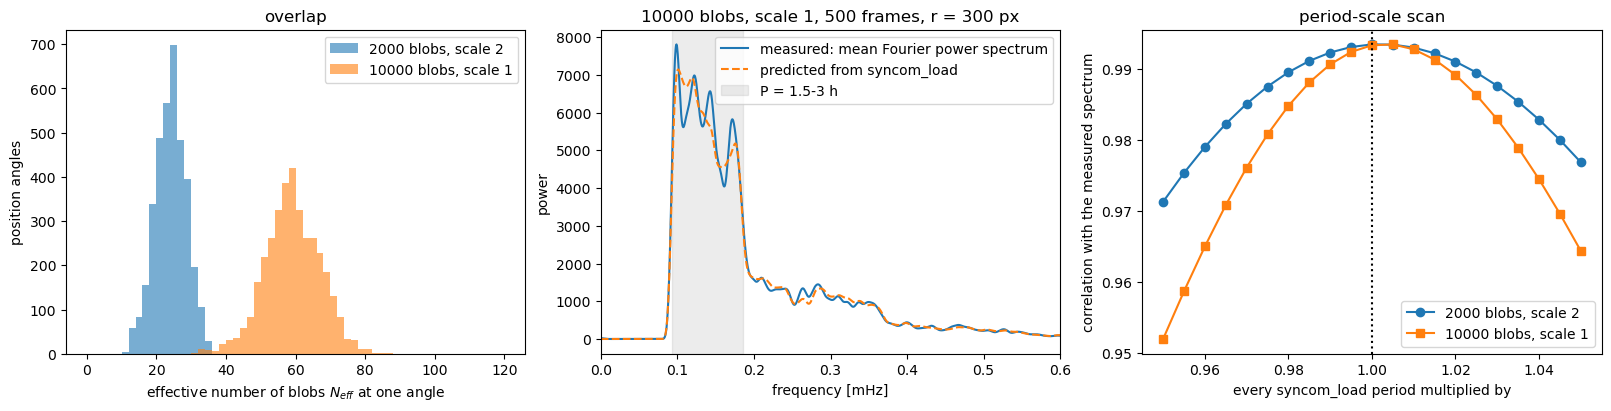

In [13]:
RUN_31 = "SynCOM_v3.1-periodic_blobs_N_BLOBS_10000_SCALE_FACTOR_1.0"
cube_31 = syncom_run_dir(RUN_31, "cubes") / f"{RUN_31}_cube.npz"


def light_curves_at(run_params, run_blobs, r_px, steps):
    """
    Brightness at radial pixel r_px for every position angle and time step, [len(steps), NX].
    Same model as syncom_image (every launch k_lo..k_hi of every blob), evaluated at one radius only.
    """
    radial = np.zeros((len(run_blobs["v"]), len(steps)))
    for j, t in enumerate(steps):
        tau, k_lo, k_hi = launch_range(run_blobs, t, run_params["syncom_ny"])
        for k in range(int(k_lo.min()), int(k_hi.max()) + 1):
            centre = run_blobs["r0"] + run_blobs["v"] * (tau - k * run_blobs["period"])
            on = (k >= k_lo) & (k <= k_hi)
            radial[:, j] += np.where(on, np.exp(-(r_px - centre) ** 2 / (2 * (2 * run_blobs["L"]) ** 2)), 0.0)
    return (angular_profiles(run_params, run_blobs).T @ radial).T


if cube_31.exists():                                         # the saved run (about 9.5 GB in memory while loading)
    saved = np.load(cube_31, allow_pickle=True)
    params_31, scale_31 = saved["params"].item(), float(saved["scale_factor"])
    blobs_31 = syncom_blob_table(params_31, saved["LoadStruc"].item(), scale_31)
    cube = saved["syncom_data"]
    T_31 = cube.shape[2]
    lc_31 = np.ascontiguousarray(cube[:, R_PROBE, :].T)                              # [time, psi]
    check = light_curves_at(params_31, blobs_31, R_PROBE, [0, T_31 - 1])
    print(f"loaded {cube_31.name}: {cube.shape}; light curves match the model to "
          f"{np.abs(check - lc_31[[0, T_31 - 1]]).max():.1e}")
    del cube, saved
else:                                                        # same run, rebuilt from the model at r = R_PROBE
    params_31 = default_syncom_prams(SYNCOM_N_BLOBS=10000, SYNCOM_SCALE_FACTOR=1.0)
    scale_31, T_31 = 1.0, 500
    blobs_31 = syncom_blob_table(params_31, syncom_load(params_31, simple=True), scale_31)
    lc_31 = light_curves_at(params_31, blobs_31, R_PROBE, range(T_31))
    print(f"{cube_31.name} not found: light curves rebuilt from the model")
gx_31 = angular_profiles(params_31, blobs_31)
print(f"{params_31['syncom_n_blobs']} blobs, scale factor {scale_31}, {T_31} frames; L = {blobs_31['L'].min():.1f}-{blobs_31['L'].max():.1f} px")


def frequency_report(run_blobs, run_gx, run_lc, n_harmonics=7):
    """
    Frequency analysis of one run from its light curves run_lc [time, psi] at one radius.

    Returns a dict with: the effective number of overlapping blobs per angle, the blobs that make
    >= 95 % of the light at their own angle and the error of their periods, the share of angles whose
    strongest Fourier line is the predicted strongest line, and the mean spectrum measured and
    predicted from the blob table (with the period-scale scan).
    """
    n_t = run_lc.shape[0]
    window = np.hanning(n_t)
    spec = np.abs(np.fft.rfft((run_lc - run_lc.mean(axis=0)) * window[:, None], n=NFFT, axis=0)) ** 2   # [freq, psi]
    band = (freq > 0.01) & (freq < 0.2)

    weight_sum = run_gx.sum(axis=0)
    n_eff = weight_sum ** 2 / (run_gx ** 2).sum(axis=0)
    psi_b = run_blobs["psi"].astype(int)
    share = run_gx[np.arange(len(psi_b)), psi_b] / weight_sum[psi_b]
    dominant = np.where(share >= 0.95)[0]

    def peak(power):
        b = (freq > 1 / 45) & (freq < 1 / 15)
        k = np.argmax(np.where(b, power, 0))
        y0, y1, y2 = np.log(power[k - 1:k + 2])
        return NFFT / (k + 0.5 * (y0 - y2) / (y0 - 2 * y1 + y2))
    period_error = np.array([peak(spec[:, psi_b[i]]) - run_blobs["period"][i] for i in dominant])

    sigma_t = 2 * run_blobs["L"] / run_blobs["v"]
    n = np.arange(1, n_harmonics + 1)[:, None]
    df = np.arange(-0.03, 0.03, 0.25 / NFFT)
    window_power = np.abs(np.exp(-2j * np.pi * df[:, None] * np.arange(n_t)) @ window) ** 2

    def lines(period):
        amplitude = 2 * sigma_t * np.sqrt(2 * np.pi) / period * np.exp(-2 * np.pi ** 2 * n ** 2 * sigma_t ** 2 / period ** 2)
        return n / period, amplitude

    f_line, amplitude = lines(run_blobs["period"])
    f_measured = freq[band][np.argmax(spec[band], axis=0)]
    agree = np.zeros(NX, bool)
    for psi in range(NX):                                    # strongest predicted line at each angle
        w = run_gx[:, psi]
        near = w > 1e-3
        a = (amplitude[:, near] * w[near]).ravel()
        f = f_line[:, near].ravel()
        a = np.where((f > 0.01) & (f < 0.2), a, 0.0)
        agree[psi] = abs(f_measured[psi] - f[np.argmax(a)]) < 1 / n_t

    def predicted(scale=1.0):
        f_l, amp = lines(run_blobs["period"] * scale)
        out = np.zeros_like(freq)
        for fl, pw in zip(f_l.ravel(), ((amp / 2) ** 2 * (run_gx ** 2).sum(axis=1)).ravel()):
            out += pw * np.interp(freq - fl, df, window_power, left=0, right=0)
        return out / NX

    measured_mean = spec.mean(axis=1)
    scales = np.round(np.arange(0.95, 1.051, 0.005), 3)
    scan = np.array([np.corrcoef(measured_mean[band], predicted(sc)[band])[0, 1] for sc in scales])
    pred = predicted()
    return {"T": n_t, "n_eff": n_eff, "n_dominant": len(dominant), "period_error": period_error,
            "agree": agree.mean(), "measured": measured_mean, "predicted": pred,
            "corr": np.corrcoef(measured_mean[band], pred[band])[0, 1],
            "power_ratio": measured_mean[band].sum() / pred[band].sum(),
            "scales": scales, "scan": scan, "best_scale": scales[np.argmax(scan)]}


rep_20 = frequency_report(blobs, gx, lc)                     # the 2000-blob run of 6b (300 frames)
rep_31 = frequency_report(blobs_31, gx_31, lc_31)            # the 10000-blob run (500 frames)

print(f"{'':52s}{'2000 blobs, scale 2':>22s}{'10000 blobs, scale 1':>24s}")
rows = [("frames / resolution elements in the P = 1.5-3 h band", lambda r: f"{r['T']} / {r['T'] * (1/18 - 1/36):.0f}"),
        ("effective number of blobs per angle (median)", lambda r: f"{np.median(r['n_eff']):.1f}"),
        ("blobs making >= 95% of the light at their angle", lambda r: f"{r['n_dominant']}"),
        ("angles whose strongest line is the predicted one", lambda r: f"{100 * r['agree']:.0f}%"),
        ("mean spectrum: correlation with syncom_load", lambda r: f"{r['corr']:.4f}"),
        ("mean spectrum: measured / predicted power", lambda r: f"{r['power_ratio']:.3f}"),
        ("best period scale", lambda r: f"{r['best_scale']:.3f}")]
for name, fmt in rows:
    print(f"{name:52s}{fmt(rep_20):>22s}{fmt(rep_31):>24s}")

fig, ax = plt.subplots(1, 3, figsize=(16, 4), layout="constrained")
bins = np.linspace(0, 120, 61)
ax[0].hist(rep_20["n_eff"], bins, alpha=0.6, label="2000 blobs, scale 2")
ax[0].hist(rep_31["n_eff"], bins, alpha=0.6, label="10000 blobs, scale 1")
ax[0].set(xlabel=r"effective number of blobs $N_{eff}$ at one angle", ylabel="position angles", title="overlap")
ax[0].legend()
mhz = freq / CADENCE * 1e3
ax[1].plot(mhz, rep_31["measured"], label="measured: mean Fourier power spectrum")
ax[1].plot(mhz, rep_31["predicted"], "--", label="predicted from syncom_load")
ax[1].axvspan(1 / 36 / CADENCE * 1e3, 1 / 18 / CADENCE * 1e3, color="gray", alpha=0.15, label="P = 1.5-3 h")
ax[1].set(xlim=(0, 0.6), xlabel="frequency [mHz]", ylabel="power", title=f"10000 blobs, scale 1, {T_31} frames, r = {R_PROBE} px")
ax[1].legend()
ax[2].plot(rep_20["scales"], rep_20["scan"], "o-", label="2000 blobs, scale 2")
ax[2].plot(rep_31["scales"], rep_31["scan"], "s-", label="10000 blobs, scale 1")
ax[2].axvline(1.0, c="k", ls=":")
ax[2].set(xlabel="every syncom_load period multiplied by", ylabel="correlation with the measured spectrum", title="period-scale scan")
ax[2].legend()
plt.show()

assert np.median(rep_31["n_eff"]) > 2 * np.median(rep_20["n_eff"])          # more overlap, not less
assert rep_31["corr"] > 0.98 and abs(rep_31["power_ratio"] - 1) < 0.10
assert abs(rep_31["best_scale"] - 1) <= 0.01

**Observed.** The cube `SynCOM_v3.1-periodic_blobs_N_BLOBS_10000_SCALE_FACTOR_1.0` (3600 × 659 × 500, scale factor 1, made with the current launch rule) was read from disk. Its light curves at 300 px match the model to $4 \times 10^{-14}$.

| | 2000 blobs, scale 2 (6b) | 10000 blobs, scale 1 |
|---|---|---|
| frames / resolution elements in the $P$ = 1.5–3 h band | 300 / 8 | 500 / 14 |
| effective number of blobs per angle $N_\text{eff}$ (median) | 24.3 | **58.9** |
| blobs making ≥ 95% of the light at their own angle | 0 | 0 |
| angles whose strongest line is the predicted strongest line | 42% | **31%** |
| mean spectrum: correlation with the `syncom_load` prediction | 0.9935 | 0.9933 |
| mean spectrum: measured / predicted power | 0.931 | **1.007** |
| best period scale | 1.000 | 1.005 |

- **More overlap, not less.** $N_\text{eff}$ grew by a factor 2.4, close to the expected $5/2 = 2.5$. Each blob is half as wide, but there are five times as many. No blob dominates its own angle in either run.
- **One period per angle is even harder to read.** The strongest line at an angle is the predicted one at only 31% of angles (42% before). The longer record resolves lines 1.7 times better, but about 59 blobs now share each angle's light, against 14 resolution elements.
- **The population of periods is measured better.** The measured mean spectrum follows the prediction closely, including the bumps that 500 frames resolve inside the band. The absolute power now agrees to 0.7% (7% before), because 10000 blobs sample the period distribution more densely. The period-scale scan peaks more sharply: a 5% error in every period lowers the correlation to 0.95–0.96, against 0.97–0.98 in the 2000-blob run. Its maximum lies between 1.000 and 1.005, one step of the scan.

**So the frequencies in this run are again exactly the `syncom_load` ones, but only as a population.** To read one period per position angle, $N_\text{eff}$ must be close to 1. Since $N_\text{eff} \propto N \cdot \text{scale}$ (≈ 24 for 2000 × 2), that needs $N \cdot \text{scale} \lesssim 100$, e.g. 200 blobs at scale 0.5. Another way is a period profile in `syncom_load` that varies smoothly with angle, so that overlapping blobs share similar periods. ✅

## 7. The 30-frame FITS sample

**Change.** `syncom_core` no longer writes a FITS file for every frame. `write_fits_frames` writes only the requested frames. The main notebook wrote time steps 0–29 of its `v3.1-periodic_blobs` run (10000 blobs, scale factor 1, 300 s cadence). The repository keeps them in `sample_FITS/`.

**Physics.** 30 frames = 2.5 h. Blobs with $P \le 30$ frames (2.5 h) reappear inside the sample. That's about 2/3 of them, since $P$ is 18–36 frames.

**Expected.**
- Each of the 30 files is float64, shape (NY, NX) = (659, 3600), with its time step in the header.
- They are **identical** to a fresh computation with `syncom_image`, since the model is deterministic and the files are not compressed.


✅ Built cube (3600, 659, 30) from 30 FITS files in /private/tmp/claude-501/-Users-valmirmoraesfilho-Downloads-SynCOM-python-main-SynCOM-python/aa5109dd-568b-4318-afee-55c888c4c127/scratchpad/syncom-v2/sample_FITS/SynCOM_v3.1-periodic_blobs_N_BLOBS_10000_SCALE_FACTOR_1.0
{'BITPIX': -64, 'NAXIS1': 3600, 'NAXIS2': 659, 'TSTEP': 7, 'TIME': 2100.0, 'CADENCE': 300.0, 'PIXEL': 0.0141875720451562, 'NBLOBS': 10000}


largest difference between the FITS sample and a fresh computation: 0.0e+00


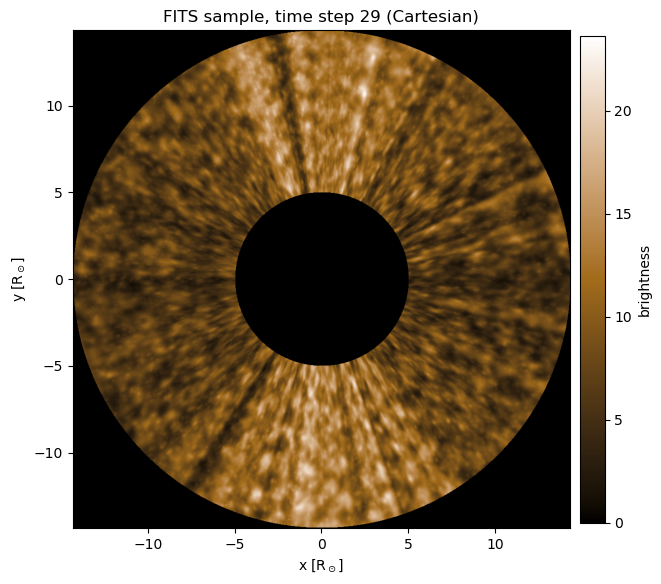

In [14]:
# The sample of the main notebook's run (6c): in the repository, or in the run folder after running it
fits_dir = Path("sample_FITS") / RUN_31
if not fits_dir.exists():
    fits_dir = syncom_run_dir(RUN_31, "fits")
sample = load_fits_cube(fits_dir, RUN_31, 0, 30, NX, NY)            # [NX, NY, 30]
assert sample is not None, "sample_FITS/ not found: run SynCOM_python_notebook.ipynb first (it writes the sample)"

header = fits.getheader(fits_dir / f"{RUN_31}_0007.fts")
print({k: header[k] for k in ("BITPIX", "NAXIS1", "NAXIS2", "TSTEP", "TIME", "CADENCE", "PIXEL", "NBLOBS")})

fresh = np.stack([syncom_image(params_31, blobs_31, t, gx=gx_31) for t in range(30)], axis=2)   # same run, recomputed
max_diff = np.abs(sample - fresh).max()
print(f"largest difference between the FITS sample and a fresh computation: {max_diff:.1e}")
assert header["BITPIX"] == -64 and (header["NAXIS1"], header["NAXIS2"]) == (NX, NY) and header["TSTEP"] == 7
assert header["NBLOBS"] == params_31["syncom_n_blobs"]
assert max_diff < 1e-12

plot_rect_image(polar_to_rect(sample[:, :, 29], POLAR_PHI_RANGE, POLAR_RHO_RANGE, n=1024),
                title="FITS sample, time step 29 (Cartesian)", cmap=cmap_punch, label="brightness")

**Observed.** - The 30 files of `sample_FITS/SynCOM_v3.1-periodic_blobs_N_BLOBS_10000_SCALE_FACTOR_1.0/` load into a `(3600, 659, 30)` cube.
- Each file is float64 (`BITPIX = -64`), 3600 × 659. The header of time step 7 has `TSTEP = 7`, `TIME = 2100 s`, the cadence, the pixel size and `NBLOBS = 10000`.
- The largest difference from a fresh computation of the same run is **0.0**: the files are bit-identical to the model.
- The Cartesian view of time step 29 is filled evenly from 5 R☉ to 14.3 R☉, with no dim ring at the occulter. ✅

## 8. Storage (for reference; no compression is applied)

FITS frames and cubes are written as uncompressed float64, the most conservative choice: no information is lost and every FITS reader can open them. The cell below measures, in memory, what **lossless** options would save on one frame, for a future decision. Nothing is written to disk.


In [15]:
import io

def size_mb(hdul):
    buffer = io.BytesIO(); hdul.writeto(buffer); return len(buffer.getvalue()) / 1e6, buffer

frame = fresh[:, :, 0].T                                                   # (NY, NX) float64
raw, _ = size_mb(fits.HDUList([fits.PrimaryHDU(frame)]))
gz, buffer = size_mb(fits.HDUList([fits.PrimaryHDU(), fits.CompImageHDU(frame, compression_type="GZIP_2", quantize_level=0.0)]))
buffer.seek(0)
identical = np.array_equal(fits.open(buffer)[1].data, frame)

print(f"float64, uncompressed (used):      {raw:6.2f} MB per frame, {raw * 300 / 1000:5.2f} GB for 300 frames")
print(f"float64, GZIP_2 lossless (not used): {gz:6.2f} MB per frame ({100 * (1 - gz / raw):.0f}% smaller), bit-identical: {identical}")
assert identical

float64, uncompressed (used):       18.98 MB per frame,  5.69 GB for 300 frames
float64, GZIP_2 lossless (not used):  15.49 MB per frame (18% smaller), bit-identical: True


**Observed.** - Uncompressed float64: 18.98 MB per frame, 5.69 GB for 300 frames.
- Lossless GZIP_2 would save 18% (15.49 MB per frame for this 10000-blob frame) and read back bit-identical.
- As requested, no compression is applied. This is recorded here for a future decision.

## 9. Summary

| check | result |
|---|---|
| `gaussian_profile` shape and 0°/360° wrap-around | ✅ |
| v2 runs out (3 of 14000 copies left at frame 299); v3 is full **from frame 0** (8435–8534 launches at every frame, 1.2% spread) | ✅ |
| a blob begins from its centre, launched $12L$ below 5 R☉ (1.3–4.7 R☉), hidden at launch, crossing 5 R☉ with value 1.000 | ✅ |
| mean brightness equal at every radius (1.000 at 5 R☉, 0.999 at the top); launching at 5 R☉ would give 0.503 | ✅ |
| one blob with $P$ = 1 h crosses 5 R☉ at frames 6, 18, …, 294, launches $vP$ = 120 px apart, field already full at $t = 0$ | ✅ |
| periodicity in the cube: autocorrelation peak at $P$ (exact for one blob, 33 vs 33.10 frames in the sparse run) | ✅ |
| full run: time-delay speed matches the input to 0.0% (fast) and 0.2% (slow) | ✅ |
| frequencies: the Fourier power spectrum recovers each dominant blob's `syncom_load` period to 0.001 frames; the full-run spectrum matches the `syncom_load` prediction (correlation 0.9935, best period scale 1.000) | ✅ |
| 10000 blobs at scale 1, 500 frames: 2.4× more overlap (one period per angle at 31% of angles), but the period population matches `syncom_load` even better (power within 0.7%, best scale 1.005) | ✅ |
| 30-frame FITS sample of the main notebook's run (10000 blobs): float64, correct headers, bit-identical to the model | ✅ |

**Conclusion.** In v3-periodic_blobs every blob reappears each time its period is up, before and during the whole simulation. Each blob is launched behind the occulter and slides into the field fully formed. The field is in steady state from the first frame, and its mean brightness is the same at every radius. The speeds and the frequencies in the cube are the ones put in by `syncom_load`, so the synthetic data can be used to validate speed- and period-measuring methods.

**Things to keep in mind**
- **Field of view:** 5–14.335 R☉. `POLAR_RHO_RANGE` is computed from `SYNCOM_PIXEL` in `syncom_prams.py`, so the plots and the simulation always use the same pixel size.
- **Overlap:** with 2000 blobs at scale 2, 50–80 blobs overlap at every position angle. Periods can be read one per position angle only where a blob dominates. Use fewer or smaller blobs if a test needs that.
- **Runtime:** the main run takes ≈3 min for 2000 blobs × 300 frames. Computing the frames takes ≈30 s; most of the rest is saving the float64 `.npz` cube.
